# Blocks and diagrams

The core of sigline, start to end: own blocks, lines, diagrams, feedback,
sample rates, sweeps, stopping and checks. Each result is checked against a
closed form or plain NumPy.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import sigline as sl

fs = 8000.0  # sample rate in Hz

## 1. Writing blocks

The library ships ready-made blocks (notebook 02). This section writes its
own, to show what every block is made of.

A block is a class derived from `sl.Block` with up to five parts:

| part | role |
| --- | --- |
| `inputs`, `outputs` | class attributes naming the ports; default `("x",)` and `("y",)` |
| `__init__(self, ..., **kw)` | stores the parameters as attributes, then calls `super().__init__(**kw)` |
| `reset(self)` | creates the state; called by `__init__` and by `d.reset()` |
| `step(self, x, ...)` | processes one chunk; one argument per input port, by name |
| `step_source(self, L)` | instead of `step` in sources (`inputs = ()`): makes `L` samples |

Rules:

1. Store parameters before `super().__init__`: it calls `reset()`, which may
   read them. `**kw` passes on `name` and `fs`.
2. Keep all state in attributes made by `reset()`; `step` updates them, so
   the next chunk continues where this one stopped.
3. `step` returns an array as long as the chunk, a tuple in `outputs` order,
   or a dict `{port: array}`. A scalar is repeated over the chunk.
4. `self.fs` is the sample rate / Hz, set by the diagram.

### Stateless, one input

Only a parameter and `step`; no `reset` needed.

In [2]:
class Gain(sl.Block):
    def __init__(self, k, **kw):
        self.k = k  # parameter first
        super().__init__(**kw)

    def step(self, x):  # input port "x", output "y"
        return self.k * x

### Several inputs

The argument names of `step` must match `inputs`.

In [3]:
class Add(sl.Block):
    inputs = ("a", "b")

    def step(self, a, b):
        return a + b

### Sources with state

No inputs, so `step_source(L)`. The tone keeps its phase in `reset()`-made
state, so it is continuous however time is cut into chunks.

In [4]:
class Tone(sl.Block):
    inputs = ()

    def __init__(self, f, amp=1.0, **kw):
        self.f, self.amp = f, amp
        super().__init__(**kw)

    def reset(self):
        self.phase = 0.0

    def step_source(self, L):
        dphi = 2 * np.pi * self.f / self.fs
        y = self.amp * np.cos(self.phase + dphi * np.arange(L))
        self.phase = (self.phase + dphi * L) % (2 * np.pi)
        return y


class Noise(sl.Block):
    inputs = ()

    def __init__(self, sigma, seed=0, **kw):
        self.sigma, self.seed = sigma, seed
        super().__init__(**kw)

    def reset(self):
        self.rng = np.random.default_rng(self.seed)

    def step_source(self, L):
        return self.sigma * self.rng.standard_normal(L)

### Sinks

No outputs, so `step` returns an empty dict.

In [5]:
class Recorder(sl.Block):
    outputs = ()

    def reset(self):
        self.chunks = []

    def step(self, x):
        self.chunks.append(x.copy())
        return {}

    @property
    def data(self):
        return np.concatenate(self.chunks) if self.chunks else np.empty(0)

### Blocks are functions too

Calling a block processes one chunk; state carries over between calls.

In [6]:
g = Gain(3.0)
print(g(np.array([1.0, 2.0, 3.0])))

tone = Tone(1000.0, fs=fs)
first, second = tone(4), tone(4)  # one chunk of 4 samples, then the next
print(np.round(np.r_[first, second], 3))
print(np.allclose(np.r_[first, second], Tone(1000.0, fs=fs)(8)))

[3. 6. 9.]
[ 1.     0.707  0.    -0.707 -1.    -0.707 -0.     0.707]
True


## 2. Lines and diagrams

`a >> b` draws a line; `block["port"]` picks a port. `Diagram` collects
everything connected to one block and runs it at `fs`.

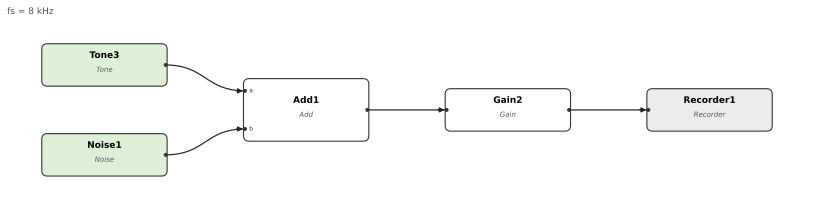

In [7]:
tone, noise, add, rec = Tone(440.0), Noise(0.1, seed=1), Add(), Recorder()
tone >> add["a"]
noise >> add["b"]
add >> Gain(0.5) >> rec

d = sl.Diagram(rec, fs=fs)
d

In [8]:
d.run(0.02, chunk=64)  # 20 ms in chunks of 64 samples
print(d.summary(chunk=64))

Diagram fs=8000 Hz, 5 blocks, chunk=64
  step   Tone3
  step   Noise1
  step   Add1
  step   Gain2
  step   Recorder1
lines:
  Tone3['y'] -> Add1['a']
  Noise1['y'] -> Add1['b']
  Gain2['y'] -> Recorder1['x']
  Add1['y'] -> Gain2['x']


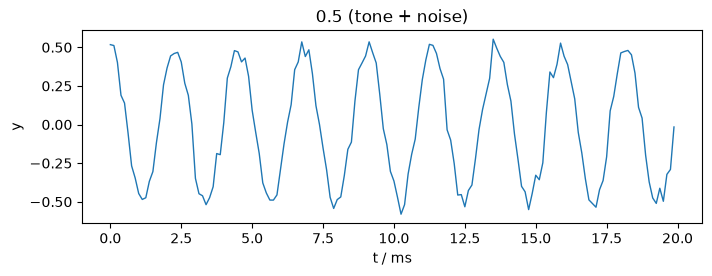

In [9]:
fig, ax = plt.subplots(figsize=(8, 2.5))
ax.plot(1e3 * d.t, rec.data, lw=1)
ax.set(xlabel="t / ms", ylabel="y", title="0.5 (tone + noise)")
plt.show()

Chunk size never changes the result. Reference: the closed form in plain
NumPy (the noise generator draws the same sequence however it is split).

In [10]:
n = np.arange(160)
rng = np.random.default_rng(1)  # same seed as the Noise block
ref = 0.5 * (np.cos(2 * np.pi * 440.0 * n / fs) + 0.1 * rng.standard_normal(160))

for chunk in [1, 7, 64, 160]:
    d.reset().run(n=160, chunk=chunk)
    print(f"chunk={chunk:4d}: max |error| = {np.max(np.abs(rec.data - ref)):.1e}")

chunk=   1: max |error| = 9.1e-15
chunk=   7: max |error| = 7.4e-15
chunk=  64: max |error| = 5.7e-15
chunk= 160: max |error| = 3.6e-15


Runs continue; parameters change between runs. The tone stays
phase-continuous across the switch.

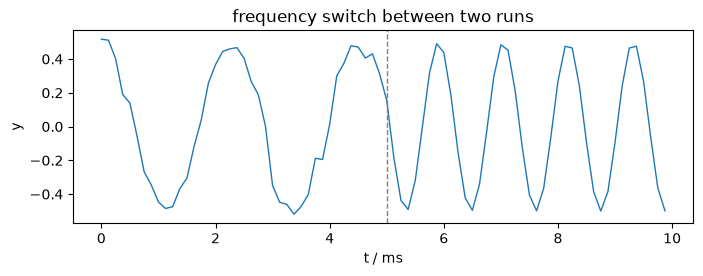

In [11]:
d.reset()
d.run(0.005)
tone.f = 880.0  # an octave up
noise.sigma = 0.0
d.run(0.005)

fig, ax = plt.subplots(figsize=(8, 2.5))
ax.plot(1e3 * d.t, rec.data, lw=1)
ax.axvline(5, color="gray", ls="--", lw=1)
ax.set(xlabel="t / ms", ylabel="y", title="frequency switch between two runs")
plt.show()

## 3. Feedback: an echo

A `StateBlock`'s output depends only on its state: `output(L)` reads it,
`update(L, **inputs)` advances it. The diagram takes these outputs first and
updates last, so a loop through one runs vectorised.

A delay by `D` qualifies for chunks of at most `D`; for longer chunks
`feedthrough(L)` says it needs its input.

In [12]:
class Delay(sl.StateBlock):
    def __init__(self, D, **kw):
        self.D = D
        super().__init__(**kw)

    def reset(self):
        self.buf = np.zeros(self.D)

    def feedthrough(self, L):
        return L > self.D

    def output(self, L):
        return self.buf[:L]

    def update(self, L, x):
        self.buf = np.concatenate([self.buf, x])[L:]

    def step(self, x):  # used when the chunk is longer than D
        full = np.concatenate([self.buf, x])
        self.buf = full[len(x) :]
        return full[: len(x)]


class Impulse(sl.Block):
    inputs = ()

    def reset(self):
        self.n = 0

    def step_source(self, L):
        y = (np.arange(self.n, self.n + L) == 0).astype(float)
        self.n += L
        return y

The adder drives the delay; the delayed signal returns through the gain.

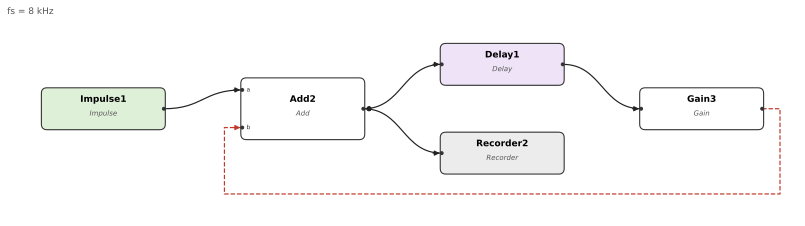

In [13]:
def echo(src, g, D):
    # y[n] = x[n] + g * y[n - D]
    add, dly, rec = Add(), Delay(D), Recorder()
    src >> add["a"]
    dly >> Gain(g) >> add["b"]
    add >> dly
    add >> rec
    return sl.Diagram(rec, fs=fs), rec


g, D = 0.6, 400  # 50 ms echo
d, rec = echo(Impulse(), g, D)
d

In [14]:
d.run(0.4, chunk=D)
print(d.summary(chunk=D))

Diagram fs=8000 Hz, 5 blocks, chunk=400
  state  Delay1
  step   Impulse1
  step   Gain3
  step   Add2
  step   Recorder2
lines:
  Impulse1['y'] -> Add2['a']
  Gain3['y'] -> Add2['b']
  Add2['y'] -> Delay1['x']
  Add2['y'] -> Recorder2['x']
  Delay1['y'] -> Gain3['x']


Impulse response of $y[n] = x[n] + g\,y[n-D]$: $g^k$ at $n = kD$, else 0.

max |error| vs closed form: 2.7755575615628914e-17


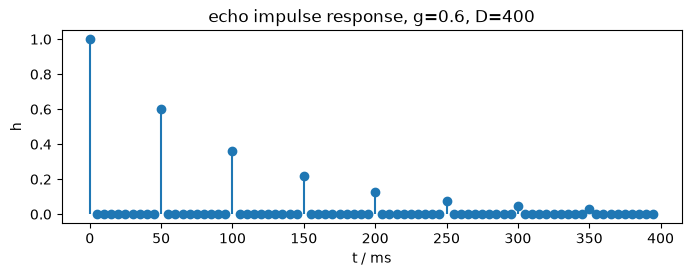

In [15]:
n = np.arange(d.n)
h = np.where(n % D == 0, g ** (n // D), 0.0)
print("max |error| vs closed form:", np.max(np.abs(rec.data - h)))

fig, ax = plt.subplots(figsize=(8, 2.5))
ax.stem(1e3 * d.t[::40], rec.data[::40], basefmt=" ")
ax.set(xlabel="t / ms", ylabel="h", title=f"echo impulse response, g={g}, D={D}")
plt.show()

A chunk longer than the delay needs the loop's output within the chunk.
The diagram runs the loop sample by sample, as a loop cluster; the rest
stays vectorised. Same result, slower. `compile_loops = False` refuses
instead.

In [16]:
ref = rec.data.copy()
d.reset().run(0.4, chunk=1024)
print(d.summary(chunk=1024).split("lines:")[0])
print("max |difference| to chunk=D:", np.max(np.abs(rec.data - ref)))

d.compile_loops = False
try:
    d.reset().run(0.4, chunk=1024)
except sl.AlgebraicLoopError as err:
    print(type(err).__name__, ":", err)
d.compile_loops = True

Diagram fs=8000 Hz, 5 blocks, chunk=1024
  step   Impulse1
  loop   loop[Add2, Delay1, Gain3]
  step   Recorder2

max |difference| to chunk=D: 0.0
AlgebraicLoopError : loop at chunk=1024 through Add2, Delay1, Gain3 needs its own output within the chunk: shorten the chunk to the loop's Delay, or set compile_loops=True


## 4. Sample rates

A block that changes the sample rate sets `resampling_ratio`, its output
rate / input rate as a `Fraction`. Rates propagate along the lines; chunks
are multiples of `d.granularity`.

Below: moving average over `M` samples, then keep every `M`-th.

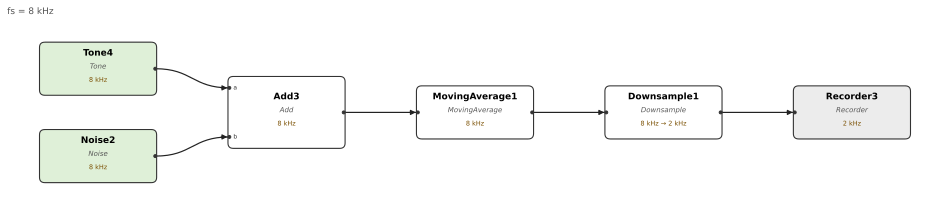

In [17]:
from fractions import Fraction


class MovingAverage(sl.Block):
    def __init__(self, M, **kw):
        self.M = M
        super().__init__(**kw)

    def reset(self):
        self.hist = np.zeros(self.M - 1)

    def step(self, x):
        full = np.concatenate([self.hist, x])
        self.hist = full[len(x) :]
        c = np.cumsum(np.r_[0.0, full])
        return (c[self.M :] - c[: -self.M]) / self.M


class Downsample(sl.Block):
    def __init__(self, M, **kw):
        self.M = M
        self.resampling_ratio = Fraction(1, M)
        super().__init__(**kw)

    def step(self, x):
        return x[:: self.M]


M = 4
tone, noise, add, rec = Tone(200.0), Noise(0.3, seed=2), Add(), Recorder()
tone >> add["a"]
noise >> add["b"]
add >> MovingAverage(M) >> Downsample(M) >> rec
d = sl.Diagram(rec, fs=fs)
d

In [18]:
for name, (f_in, f_out) in d.rates().items():
    print(f"{name:15s} {f_in:6.0f} Hz -> {f_out:6.0f} Hz")
print("granularity:", d.granularity)

Tone4             8000 Hz ->   8000 Hz
Noise2            8000 Hz ->   8000 Hz
Add3              8000 Hz ->   8000 Hz
Recorder3         2000 Hz ->   2000 Hz
MovingAverage1    8000 Hz ->   8000 Hz
Downsample1       8000 Hz ->   2000 Hz
granularity: 4


samples: 100  max |error|: 4.551914400963142e-15


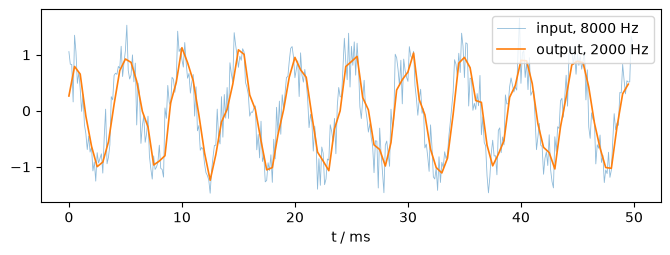

In [19]:
d.run(0.05, chunk=1001)  # chunk rounds down to 1000, a multiple of 4

# reference: the same chain computed in one go with numpy
n = np.arange(int(0.05 * fs))
rng = np.random.default_rng(2)
x = np.cos(2 * np.pi * 200.0 * n / fs) + 0.3 * rng.standard_normal(len(n))
ref = np.convolve(x, np.ones(M) / M)[: len(n)][::M]
print("samples:", len(rec.data), " max |error|:", np.max(np.abs(rec.data - ref)))

fig, ax = plt.subplots(figsize=(8, 2.5))
ax.plot(1e3 * n / fs, x, lw=0.6, alpha=0.5, label=f"input, {fs:.0f} Hz")
t_out = 1e3 * np.arange(len(rec.data)) * M / fs
ax.plot(t_out, rec.data, lw=1.2, label=f"output, {fs / M:.0f} Hz")
ax.set(xlabel="t / ms")
ax.legend(loc="upper right")
plt.show()

## 5. A sweep is a `for` loop

Change an attribute, reset, run. Echo gain swept with white noise in; theory:
output variance $\sigma^2 / (1 - g^2)$.

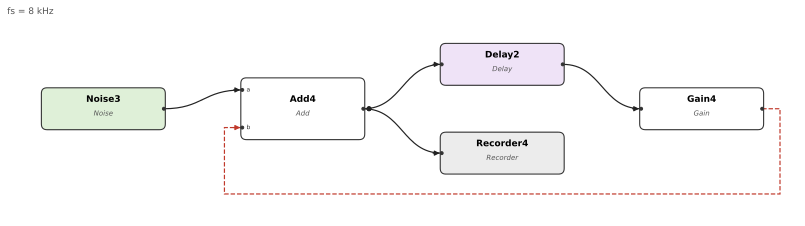

In [20]:
sigma, D = 1.0, 64
noise, add, dly, gain = Noise(sigma, seed=3), Add(), Delay(D), Gain(0.0)
rec = Recorder()
noise >> add["a"]
dly >> gain >> add["b"]
add >> dly
add >> rec
d = sl.Diagram(rec, fs=fs)
d

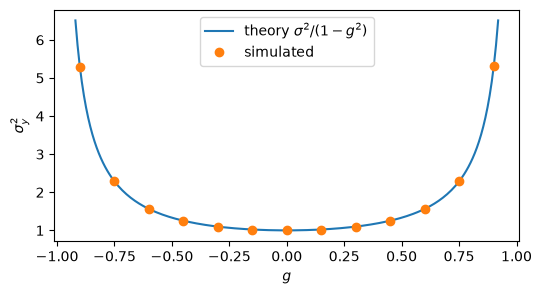

largest relative deviation: 1.0%


In [21]:
gains = np.linspace(-0.9, 0.9, 13)
measured = []
for k in gains:
    gain.k = k
    d.reset().run(n=200_000, chunk=D)
    measured.append(np.var(rec.data[1000:]))  # skip the start-up transient


def theory(g):
    return sigma**2 / (1 - g**2)


fine = np.linspace(-0.92, 0.92, 200)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(fine, theory(fine), label=r"theory $\sigma^2/(1-g^2)$")
ax.plot(gains, measured, "o", label="simulated")
ax.set(xlabel="$g$", ylabel=r"$\sigma_y^2$")
ax.legend()
plt.show()
dev = np.max(np.abs(np.array(measured) / theory(gains) - 1))
print(f"largest relative deviation: {dev:.1%}")

## 6. Stopping early

`self.request_stop(reason)` ends the run after the chunk; `d.stopped` says
why.

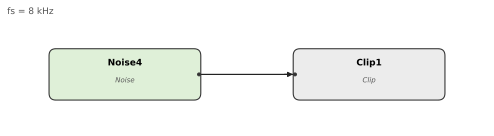

In [22]:
class Clip(sl.Block):
    outputs = ()

    def __init__(self, limit, **kw):
        self.limit = limit
        super().__init__(**kw)

    def step(self, x):
        if np.any(np.abs(x) > self.limit):
            self.request_stop(f"|x| exceeded {self.limit}")
        return {}


noise, clip = Noise(1.0, seed=4), Clip(4.0)
noise >> clip
d = sl.Diagram(clip, fs=fs)
d

In [23]:
d.run(60.0, chunk=256)
print(f"stopped after {d.n} samples ({d.n / fs:.2f} s): {d.stopped}")

stopped after 1280 samples (0.16 s): Clip1: |x| exceeded 4.0


## 7. Checks

The first chunk after build or `reset()` is checked: NaN/Inf and dropped
imaginary parts raise an error naming the first block at fault.
`check=True` checks every chunk, `check=False` never.

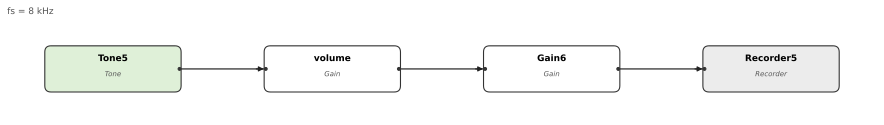

In [24]:
tone, gain, rec = Tone(440.0), Gain(1.0, name="volume"), Recorder()
tone >> gain >> Gain(0.5) >> rec
d = sl.Diagram(rec, fs=fs)
d

In [25]:
gain.k = float("inf")  # a bad parameter value
try:
    d.run(0.01)
except FloatingPointError as err:
    print(err)

volume['y'] (Gain) produced NaN/Inf at sample 0 of this chunk; its inputs were finite, so this block is the first one to fail


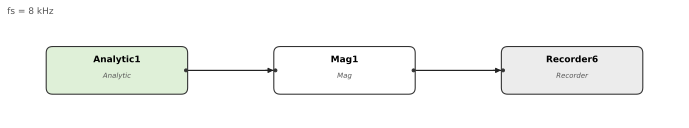

In [26]:
class Mag(sl.Block):
    def step(self, x):
        y = np.empty(len(x))
        y[:] = x  # meant np.abs(x): this silently drops the imaginary part
        return y


class Analytic(sl.Block):
    inputs = ()

    def step_source(self, L):
        return np.exp(2j * np.pi * 0.01 * np.arange(L))


src, mag, rec = Analytic(), Mag(), Recorder()
src >> mag >> rec
d = sl.Diagram(rec, fs=fs)
d

In [27]:
try:
    d.run(n=100)
except TypeError as err:
    print(err)

Mag1 (Mag) dropped the imaginary part of a complex signal; inputs: x: complex128


## Summary

- Blocks: parameters as attributes, state in `reset()`, one chunk per
  `step`; usable as functions.
- `>>` draws lines; `Diagram` runs them; chunking never changes results.
- `StateBlock`s break loops; other loops run sample by sample.
- `resampling_ratio` changes sample rates.
- Sweeps are `for` loops; `request_stop` ends runs; checks name the faulty
  block.